## 회귀 모델로 몸무게 예측하기


In [126]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

SEED = 42
model_results = {}  # 모델 이름별 평가 결과를 저장한다.


### 회귀란 무엇인가

회귀(regression)는 입력 변수와 수치형 목표 변수 사이의 관계를 분석하고, 그 관계를 바탕으로 값을 예측하는 방법이다.

| 입력 정보 | 예측하려는 값 |
| --- | --- |
| 펭귄의 날개 길이 | 몸무게(g) |
| 집의 면적·위치·건축 연도 | 집값(원) |
| 이동 거리·시간대·교통 상황 | 소요 시간(분) |

### 회귀 모델은 어떻게 학습할까

모델에 제공하는 정보를 입력 `X`, 예측하려는 실제 수치값을 정답 `y`라고 한다. 입력과 정답이 짝지어진 데이터로 학습하는 방식을 지도학습이라고 한다.

회귀 모델은 학습 데이터의 예측값과 정답 사이의 오차가 작아지도록 입력과 정답의 관계를 학습한다. 학습한 모델에 새로운 입력을 전달하면 수치형 예측값을 계산한다.

```text
학습: 입력 X + 정답 y → 입력과 정답의 관계 학습
예측: 새로운 입력 X → 학습한 모델 → 수치형 예측값
```


### 펭귄 몸무게 예측

펭귄의 날개 길이를 입력으로 받아 몸무게를 예측하는 문제다.
단순 선형 회귀로 날개 길이와 몸무게 사이의 관계를 직선으로 표현한다.

### 펭귄 데이터 불러오기

`penguins`에는 펭귄 344마리의 관측 기록이 있다. 한 행은 펭귄 한 마리다.

| 역할 | 열 | 의미와 단위 |
| --- | --- | --- |
| 입력 | `flipper_length_mm` | 날개 길이, mm |
| 정답 | `body_mass_g` | 몸무게, g |

몸무게가 기록되지 않은 2마리를 제외한 342마리의 데이터를 사용한다.

입력 `X`는 2차원 표이고, 정답 `y`는 몸무게 한 열이다. 입력 열이 하나여도 `X`는 2차원으로 유지한다.


In [2]:
penguins = sns.load_dataset("penguins")
print("전체 데이터:", penguins.shape)
display(penguins.head())

# subset에 지정한 몸무게 열이 비어 있는 행만 제외한다.
penguin_data = penguins.dropna(subset=["body_mass_g"]).copy()
X = penguin_data[["flipper_length_mm"]].copy()  # DataFrame, (342, 1)
y = penguin_data["body_mass_g"].copy()  # Series, (342,)

print("정답이 없는 행:", penguins["body_mass_g"].isna().sum())
print("입력과 정답:", X.shape, y.shape)
display(X.isna().sum().rename("missing_count"))
display(pd.concat([X, y], axis=1).head())


전체 데이터: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


정답이 없는 행: 2
입력과 정답: (342, 1) (342,)


flipper_length_mm    0
Name: missing_count, dtype: int64

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
4,193.0,3450.0
5,190.0,3650.0


### 학습·검증·테스트 분리

| 구간 | 역할 |
| --- | --- |
| 학습 | 전처리 기준과 모델의 가중치를 구한다 |
| 검증 | 모델의 오차를 비교하고 사용할 모델을 고른다 |
| 테스트 | 선택을 끝낸 모델을 마지막에 평가한다 |

먼저 전체의 약 20%를 테스트로 떼어 두고, 나머지의 25%를 검증으로 나눈다. 전체 기준 약 60%·20%·20%이며 `X`와 `y`를 함께 나눠 같은 행끼리 대응시킨다.
검증·테스트 데이터에는 전처리 기준이나 모델을 다시 학습하지 않는다.


In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,  # 분리해 남길 테스트 데이터의 비율
    random_state=SEED,  # 같은 무작위 분리를 재현한다.
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=SEED)

print("학습:", X_train.shape, y_train.shape)
print("검증:", X_val.shape, y_val.shape)
print("테스트:", X_test.shape, y_test.shape)


학습: (204, 1) (204,)
검증: (69, 1) (69,)
테스트: (69, 1) (69,)


### 선형 회귀의 기울기와 절편

입력이 날개 길이 하나라면 선형 회귀는 다음 식으로 예측한다.

```text
예측 몸무게 = 기울기 × 날개 길이 + 절편
```

기울기는 입력이 1만큼 증가할 때 예측값이 얼마나 변하는지를 나타낸다. 기울기가 50이라면 날개 길이가 1mm 증가할 때 예측 몸무게가 50g 증가한다.

절편(intercept)은 입력이 0일 때 식이 계산하는 예측값이다. 직선식 `y = ax + b`에서 `b`에 해당하며, 직선이 y축과 만나는 지점의 y값이므로 y절편이라고도 한다. 기울기를 고정한 채 절편을 키우면 직선 전체가 위로, 줄이면 아래로 이동한다. 절편은 관측한 데이터에 맞게 예측 직선의 높이를 조정하는 역할을 한다.

### 잔차와 MSE

잔차는 실제값에서 예측값을 뺀 값이다.
MSE(평균 제곱 오차)는 잔차를 제곱한 뒤 평균 낸 값이다. 양수와 음수 잔차가 서로 상쇄되지 않도록 제곱하며, 값이 작을수록 예측이 실제값에 가깝다.

$n$은 사례 수, $y_i$는 $i$번째 사례의 실제값, $\hat{y}_i$는 예측값이다. $\sum_{i=1}^{n}$은 첫 번째부터 $n$번째 사례까지 모두 더한다는 뜻이다.

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

즉, 각 사례의 잔차를 제곱하고 모두 더한 뒤 사례 수로 나눈다. 몸무게의 단위가 g이면 MSE의 단위는 g²이다.

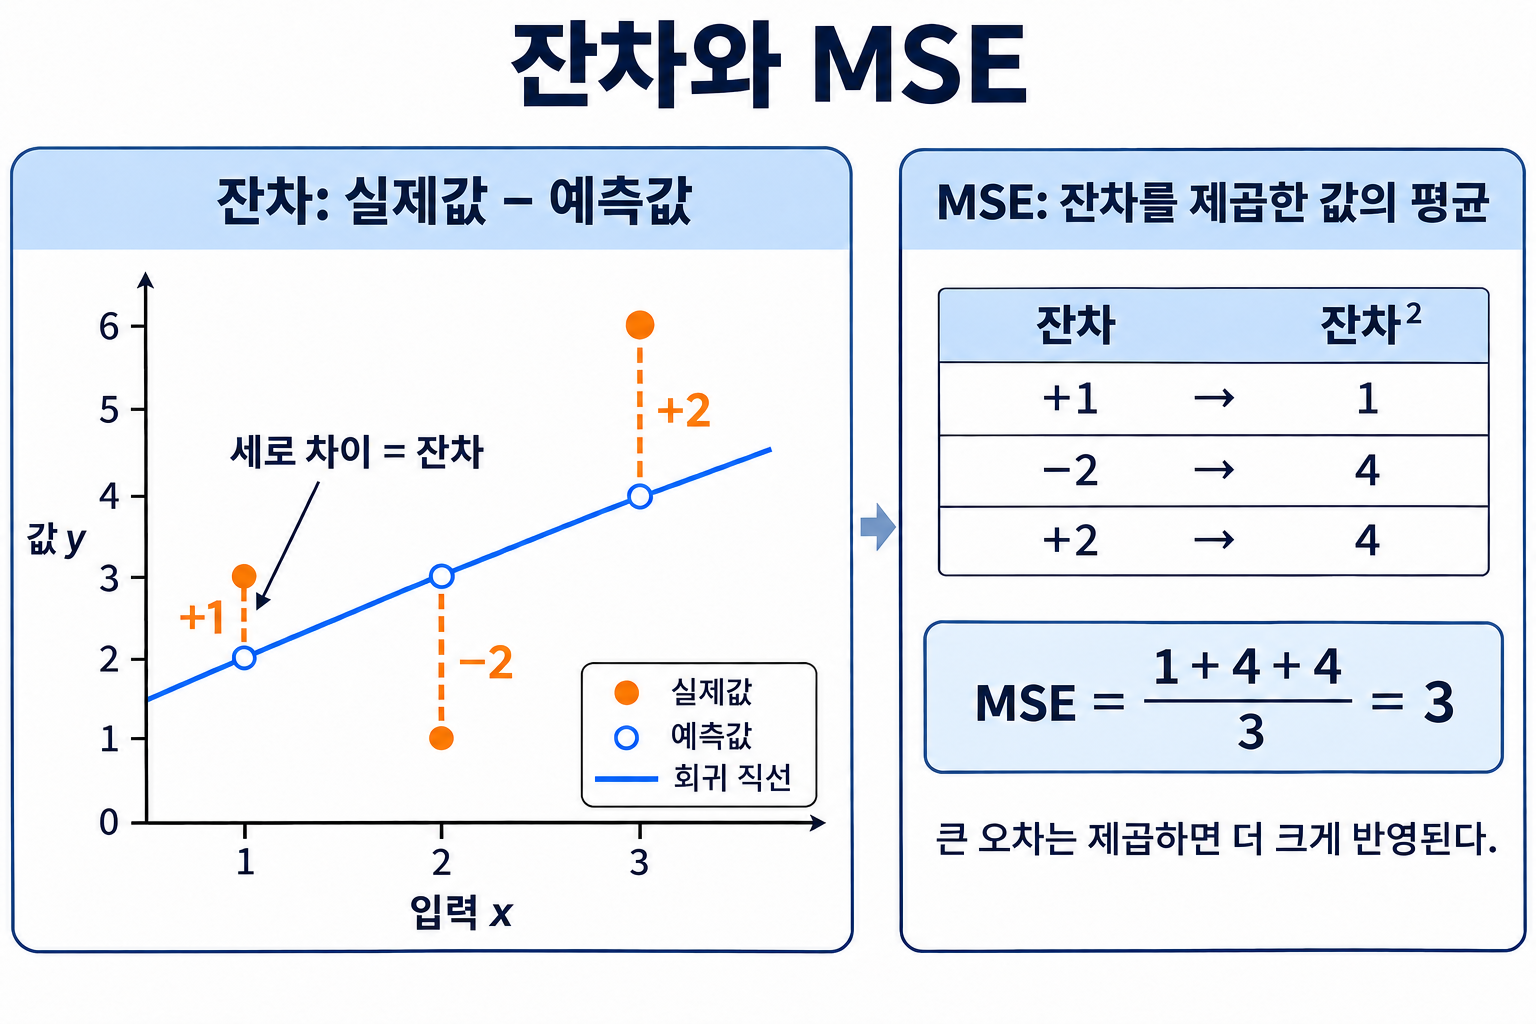

### 선형 회귀의 손실 함수

손실 함수(loss function)는 학습할 때 예측 오차를 수치로 나타내는 함수다. 선형 회귀에서는 MSE를 손실 함수로 사용한다.

$x_i$는 $i$번째 펭귄의 날개 길이, $w$는 기울기, $b$는 절편이다. 예측식 $\hat{y}_i=wx_i+b$를 MSE 식에 넣으면 다음과 같다.

$$
L(w,b)=\frac{1}{n}\sum_{i=1}^{n}\bigl(y_i-(wx_i+b)\bigr)^2
$$

$L(w,b)$는 기울기와 절편을 정했을 때 계산되는 손실이다. 학습 데이터의 $x_i$와 $y_i$는 고정되어 있고, 모델은 $L(w,b)$가 가장 작아지는 $w$와 $b$를 찾는다.


### 모델 학습과 예측

`LinearRegression`에 날개 길이와 몸무게를 전달하면 예측 직선의 기울기와 절편을 구한다.  
입력 변수가 하나인 선형 회귀를 단순 선형 회귀라고 한다.


In [4]:
simple_model = LinearRegression()
# fit: 2차원 입력 X와 1차원 정답 y로 모델을 학습한다.
simple_model.fit(X_train, y_train)
# predict: 검증 입력의 각 행에 대한 예측값을 (검증 행 수,) 배열로 반환한다.
simple_val_prediction = simple_model.predict(X_val)

# coef_: 입력 열별 가중치 배열, intercept_: 절편 값
print("기울기(g/mm):", simple_model.coef_[0])
print("절편(g):", simple_model.intercept_)
display(pd.DataFrame({
    "flipper_length_mm": X_val["flipper_length_mm"],
    "actual_g": y_val,
    "predicted_g": simple_val_prediction,
}).head())


기울기(g/mm): 48.039294728647995
절편(g): -5445.272523068824


,flipper_length_mm,actual_g,predicted_g
194,196.0,3550.0,3970.429244
297,220.0,6000.0,5123.372317
240,218.0,5700.0,5027.293728
270,210.0,4850.0,4642.979370
202,199.0,3325.0,4114.547128


### 회귀 직선 읽기

점은 실제 관측값이고, 직선은 날개 길이에 따른 예측 몸무게를 나타낸다. 같은 날개 길이에서 점과 직선의 세로 간격이 작을수록 예측 오차가 작다.


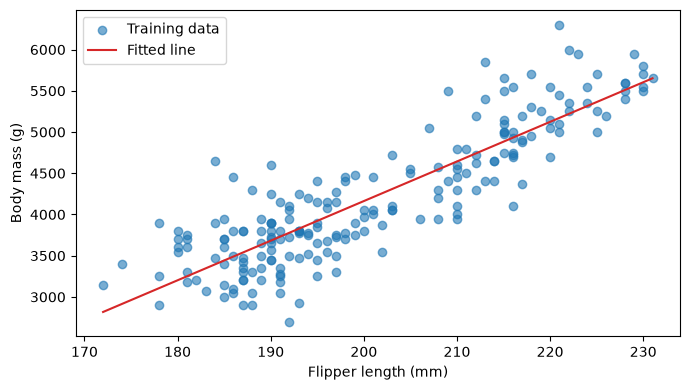

In [5]:
# linspace: 학습 범위의 최솟값부터 최댓값까지 일정한 간격의 값 100개를 만든다.
line_X = pd.DataFrame({
    "flipper_length_mm": np.linspace(
        X_train["flipper_length_mm"].min(),
        X_train["flipper_length_mm"].max(),
        100,
    ),
})
line_prediction = simple_model.predict(line_X)

plt.figure(figsize=(7, 4))
plt.scatter(X_train["flipper_length_mm"], y_train, alpha=0.6, label="Training data")
plt.plot(line_X["flipper_length_mm"], line_prediction, color="tab:red", label="Fitted line")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.legend()
plt.tight_layout()
plt.show()


### MAE와 RMSE

평가 지표는 모델의 예측이 얼마나 좋은지 비교하는 기준이다.

- MAE: 잔차의 절댓값을 평균 낸 값이다.
- RMSE: 제곱 오차 평균의 양의 제곱근이다. 큰 오차에 더 민감하게 반응한다.

두 지표 모두 정답과 같은 단위로 읽고 작을수록 좋다. 선형 회귀는 제곱 오차로 학습하지만 모델 비교에는 MAE도 사용할 수 있다.

학습 데이터의 처음 세 마리에 대한 실제 몸무게와 모델 예측값으로 MAE와 RMSE를 계산한다.


In [127]:
small_X = X_train.head(3)
# 선택한 입력과 같은 행의 실제 몸무게를 가져온다.
actual_small = y_train.loc[small_X.index].to_numpy()
predicted_small = simple_model.predict(small_X)
error = actual_small - predicted_small

display(pd.DataFrame({
    "flipper_length_mm": small_X["flipper_length_mm"],
    "actual_g": actual_small,
    "predicted_g": predicted_small,
    "residual_g": error,
    "absolute_error_g": np.abs(error),
}))
print("MAE(g):", np.abs(error).mean())
print("RMSE(g):", np.sqrt((error ** 2).mean()))


,flipper_length_mm,actual_g,predicted_g,residual_g,absolute_error_g
24,180.0,3800.0,3201.800528,598.199472,598.199472
324,216.0,4725.0,4931.215138,-206.215138,206.215138
118,189.0,3350.0,3634.154181,-284.154181,284.154181


MAE(g): 362.85626362565836
RMSE(g): 400.4626032671043


### 결정계수 R²

결정계수 $R^2$는 모델의 제곱 오차를, 모든 사례를 실제값의 평균으로 예측했을 때의 제곱 오차와 비교하는 지표다.
MAE·RMSE는 실제 단위로 오차 크기를 나타내고, R²는 평균 예측을 기준으로 제곱 오차를 줄인 비율을 나타낸다.

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

$n$은 평가 사례 수, $y_i$는 실제값, $\hat{y}_i$는 모델 예측값이다. $\bar{y}$는 평가하는 데이터의 실제값 평균이다.
검증 R²를 계산할 때는 검증 정답의 평균을, 테스트 R²를 계산할 때는 테스트 정답의 평균을 비교 기준으로 쓴다.
분자는 모델의 제곱 오차 합이고, 분모는 실제값의 평균으로 예측한 제곱 오차 합이다. 이 식은 실제값에 변동이 있어 분모가 0보다 클 때 적용한다.

| R² | 의미 |
| --- | --- |
| 1 | 모든 예측값이 실제값과 일치한다 |
| 0 | 평균으로 예측한 기준과 제곱 오차가 같다 |
| 음수 | 평균으로 예측한 기준보다 제곱 오차가 크다 |

R²는 단위가 없으며, 같은 평가 데이터에서 값이 클수록 좋다. 예를 들어 R²가 0.8이면 평균 예측 기준보다 제곱 오차를 80% 줄였다는 뜻이다.


### 학습·검증 평가 결과 기록

학습 RMSE·R²와 검증 RMSE·MAE·R²를 계산하고 `model_results`에 모델 이름별로 저장한다.
학습 오차와 검증 오차를 비교해 학습에 사용하지 않은 데이터에서도 잘 예측하는지 확인한다.


In [128]:
# r2_score: (사례 수,) 모양의 실제값과 예측값을 받아 R²를 실수로 반환한다.
model_results["simple"] = {
    "model": "simple",
    "train_RMSE_g": np.sqrt(mean_squared_error(y_train, simple_model.predict(X_train))),
    "val_RMSE_g": np.sqrt(mean_squared_error(y_val, simple_val_prediction)),
    "val_MAE_g": mean_absolute_error(y_val, simple_val_prediction),
    "train_R2": r2_score(y_train, simple_model.predict(X_train)),
    "val_R2": r2_score(y_val, simple_val_prediction),
}
model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2
0,simple,395.672383,399.914148,321.919229,0.75594,0.738302


### 실제값과 예측값 비교

가로축은 실제 몸무게, 세로축은 단순 회귀의 예측 몸무게다. 점 하나는 검증 펭귄 한 마리이며, 대각선에 가까울수록 예측 오차가 작다.
대각선 아래의 점은 실제보다 작게 예측한 경우, 위의 점은 크게 예측한 경우다.


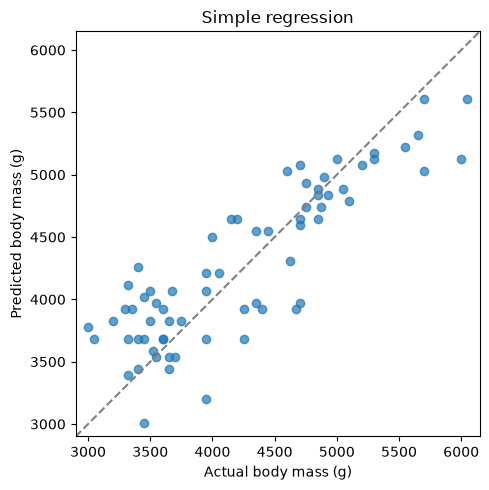

In [129]:
all_values = np.concatenate([y_val.to_numpy(), simple_val_prediction])
limits = [all_values.min() - 100, all_values.max() + 100]

plt.figure(figsize=(5, 5))
plt.scatter(y_val, simple_val_prediction, alpha=0.7)
plt.plot(limits, limits, "--", color="gray")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual body mass (g)")
plt.ylabel("Predicted body mass (g)")
plt.title("Simple regression")
plt.tight_layout()
plt.show()


## 다항 회귀

### 다항 회귀는 무엇인가

날개 길이와 몸무게의 관계가 직선에서 벗어나 휘어 있다면, 직선 하나로는 그 형태를 충분히 표현하기 어렵다. 다항 회귀는 입력의 제곱·세제곱 등을 이용해 곡선 관계를 표현한다.
날개 길이를 `x`라고 할 때 2차 다항 회귀의 예측식은 다음과 같다.

```text
예측 몸무게 = 가중치₁ × x + 가중치₂ × x² + 절편
```

차수는 사용하는 항에서 가장 큰 지수다. 2차는 `x`와 `x²`, 3차는 `x`, `x²`, `x³`을 사용한다. 새 측정값을 추가하는 것이 아니라 같은 날개 길이에서 입력 특성을 만든다.
다항 회귀는 입력의 제곱·세제곱 등을 새로운 특성으로 만들고, 선형 회귀로 학습해 곡선 관계를 표현한다.

### 다항 특성 만들기

`PolynomialFeatures`는 입력에서 다항 특성을 만드는 변환기다. 날개 길이 하나를 2차로 변환하면 날개 길이와 그 제곱을 담은 두 열이 만들어진다.


In [130]:
POLYNOMIAL_DEGREE = 2
# degree: 최대 차수. include_bias=False: 상수 1인 열을 만들지 않는다.
# 절편은 LinearRegression에서 구한다.
polynomial_features = PolynomialFeatures(degree=POLYNOMIAL_DEGREE, include_bias=False)
# fit_transform: 학습 입력에 맞춰 변환기를 설정하고 다항 특성 배열을 반환한다.
X_train_poly = polynomial_features.fit_transform(X_train)
# transform: 같은 변환기로 검증 입력을 변환한다.
X_val_poly = polynomial_features.transform(X_val)

print("변환 전:", X_train.shape, "변환 후:", X_train_poly.shape)
display(pd.DataFrame(
    X_train_poly[:3],
    columns=polynomial_features.get_feature_names_out(),  # 생성된 특성의 이름
))


변환 전: (204, 1) 변환 후: (204, 2)


,flipper_length_mm,flipper_length_mm^2
0,180.0,32400.0
1,216.0,46656.0
2,189.0,35721.0


### 다항 특성 표준화

거듭제곱으로 열의 크기 차이가 커지므로, 만든 특성을 표준화해 수치 계산을 안정적으로 한다.
`StandardScaler`는 학습 평균을 빼고 학습 표준편차로 나누는 변환기다. 검증 입력에도 학습 데이터에서 구한 평균과 표준편차를 사용한다.


In [131]:
polynomial_scaler = StandardScaler()
# 학습 특성으로 평균과 표준편차를 구하고 변환한다.
X_train_poly_scaled = polynomial_scaler.fit_transform(X_train_poly)
# 검증 특성은 학습한 기준으로만 변환한다.
X_val_poly_scaled = polynomial_scaler.transform(X_val_poly)

# 같은 학습 행의 다항 특성을 표준화 전후로 비교한다.
polynomial_columns = polynomial_features.get_feature_names_out()
display(pd.concat({
    "표준화 전": pd.DataFrame(X_train_poly, columns=polynomial_columns, index=X_train.index),
    "표준화 후": pd.DataFrame(X_train_poly_scaled, columns=polynomial_columns, index=X_train.index),
}, axis=1).head().round(3))


표준화 전                                 표준화 후  \
    flipper_length_mm flipper_length_mm^2 flipper_length_mm   
24              180.0             32400.0            -1.452   
324             216.0             46656.0             1.032   
118             189.0             35721.0            -0.831   
65              192.0             36864.0            -0.624   
116             188.0             35344.0            -0.900   

                         
    flipper_length_mm^2  
24               -1.395  
324               1.022  
118              -0.832  
65               -0.638  
116              -0.896

### 모델 학습과 직선·곡선 비교

`LinearRegression`에 변환한 학습 특성과 몸무게를 전달해 모델을 학습한다.
예측할 때도 다항 특성 생성과 표준화를 거친 입력을 전달한다.

단순 회귀와 다항 회귀는 같은 학습 데이터의 날개 길이와 몸무게를 사용한다. 점은 학습 관측값이며, 두 선은 같은 날개 길이 범위에서 계산한 예측이다.
곡선이 어느 구간에서 직선과 다르게 예측하는지 살펴본다.


다항 회귀의 검증 예측 모양: (69,)


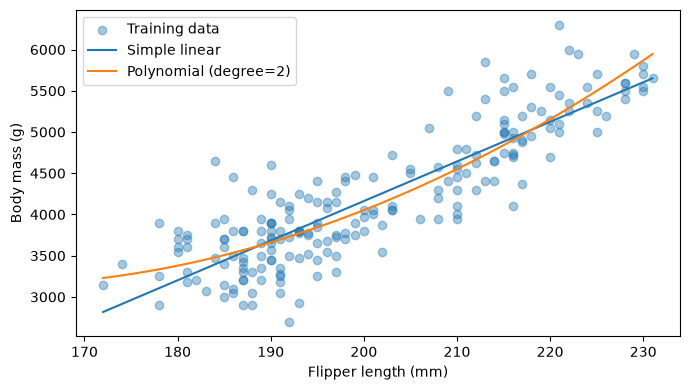

In [132]:
polynomial_model = LinearRegression()
polynomial_model.fit(X_train_poly_scaled, y_train)
# 검증 데이터의 몸무게를 예측한다.
polynomial_val_prediction = polynomial_model.predict(X_val_poly_scaled)
print("다항 회귀의 검증 예측 모양:", polynomial_val_prediction.shape)

# 곡선을 그리기 위해 일정한 간격의 날개 길이에서 예측값을 계산한다.
line_poly = polynomial_features.transform(line_X)
line_poly_scaled = polynomial_scaler.transform(line_poly)
polynomial_line_prediction = polynomial_model.predict(line_poly_scaled)

plt.figure(figsize=(7, 4))
plt.scatter(X_train["flipper_length_mm"], y_train, alpha=0.4, label="Training data")
plt.plot(line_X["flipper_length_mm"], line_prediction, label="Simple linear")
plt.plot(line_X["flipper_length_mm"], polynomial_line_prediction,
         label=f"Polynomial (degree={POLYNOMIAL_DEGREE})")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.legend()
plt.tight_layout()
plt.show()


### 학습·검증 평가 결과 비교

두 모델의 학습 RMSE와 검증 RMSE를 비교하고, 검증 MAE로 평균적인 절대 오차도 확인한다. MAE·RMSE의 단위는 g이다. 학습·검증 R²로 평균 예측 대비 제곱 오차를 줄인 비율도 확인한다.
모델이 학습 데이터의 우연한 변동까지 맞추어 새 데이터에서는 잘 예측하지 못하는 것을 과적합이라고 한다. 모델을 복잡하게 만들었을 때 학습 오차는 줄어도 검증 오차가 커진다면 과적합을 의심할 수 있다.
2차 다항 회귀가 단순 회귀보다 검증 오차를 줄이는지는 실제 계산 결과로 판단한다.


In [133]:
model_results["polynomial_2"] = {
    "model": "polynomial_2",
    "train_RMSE_g": np.sqrt(mean_squared_error(y_train, polynomial_model.predict(X_train_poly_scaled))),
    "val_RMSE_g": np.sqrt(mean_squared_error(y_val, polynomial_val_prediction)),
    "val_MAE_g": mean_absolute_error(y_val, polynomial_val_prediction),
    "train_R2": r2_score(y_train, polynomial_model.predict(X_train_poly_scaled)),
    "val_R2": r2_score(y_val, polynomial_val_prediction),
}
model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2
0,simple,395.672383,399.914148,321.919229,0.755940,0.738302
1,polynomial_2,381.698484,372.456739,296.171582,0.772874,0.773004


### 다항식 차수 바꾸기

같은 학습·검증 데이터로 3차 다항 회귀를 학습한다. 3차는 날개 길이 `x`에서 `x`, `x²`, `x³`의 세 특성을 만든다.
3차용 변환기와 모델을 새로 만들고, 특성 생성 → 표준화 → 모델 학습 순서로 실행한다.


In [134]:
cubic_features = PolynomialFeatures(degree=3, include_bias=False)
X_train_cubic = cubic_features.fit_transform(X_train)
X_val_cubic = cubic_features.transform(X_val)

cubic_scaler = StandardScaler()
X_train_cubic_scaled = cubic_scaler.fit_transform(X_train_cubic)
X_val_cubic_scaled = cubic_scaler.transform(X_val_cubic)

cubic_model = LinearRegression()
cubic_model.fit(X_train_cubic_scaled, y_train)
cubic_val_prediction = cubic_model.predict(X_val_cubic_scaled)
print("3차 학습 특성 모양:", X_train_cubic_scaled.shape)


3차 학습 특성 모양: (204, 3)


### 차수별 결과 비교

누적된 평가 표에서 단순 선형 회귀·2차·3차의 학습·검증 RMSE와 R², 검증 MAE를 비교하고, 직선과 두 곡선을 같은 날개 길이 범위에서 그린다.

- 차수를 높였을 때 곡선의 휘어짐이 어떻게 달라졌는가?
- 학습·검증 RMSE와 MAE는 어떻게 달라졌는가? R²의 변화 방향은 어떠한가?
- 학습 오차만 줄고 검증 오차가 커졌다면, 더 높은 차수가 새 데이터의 예측에 도움이 되었다고 할 수 있는가?


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2
0,simple,395.672383,399.914148,321.919229,0.755940,0.738302
1,polynomial_2,381.698484,372.456739,296.171582,0.772874,0.773004
2,polynomial_3,376.839482,367.141773,283.700001,0.778620,0.779436


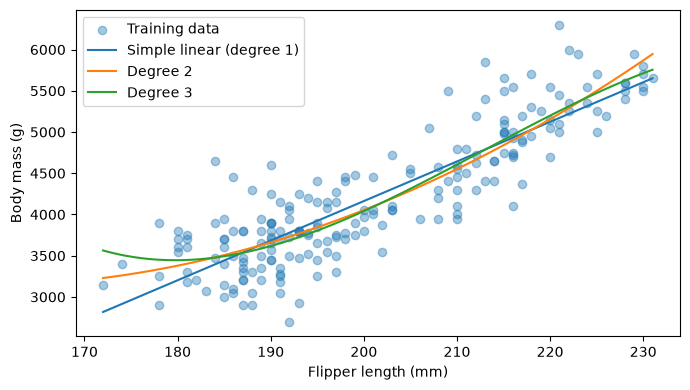

In [135]:
model_results["polynomial_3"] = {
    "model": "polynomial_3",
    "train_RMSE_g": np.sqrt(mean_squared_error(y_train, cubic_model.predict(X_train_cubic_scaled))),
    "val_RMSE_g": np.sqrt(mean_squared_error(y_val, cubic_val_prediction)),
    "val_MAE_g": mean_absolute_error(y_val, cubic_val_prediction),
    "train_R2": r2_score(y_train, cubic_model.predict(X_train_cubic_scaled)),
    "val_R2": r2_score(y_val, cubic_val_prediction),
}
model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)

line_cubic = cubic_features.transform(line_X)
line_cubic_scaled = cubic_scaler.transform(line_cubic)
cubic_line_prediction = cubic_model.predict(line_cubic_scaled)

plt.figure(figsize=(7, 4))
plt.scatter(X_train["flipper_length_mm"], y_train, alpha=0.4, label="Training data")
plt.plot(line_X["flipper_length_mm"], line_prediction, label="Simple linear (degree 1)")
plt.plot(line_X["flipper_length_mm"], polynomial_line_prediction, label="Degree 2")
plt.plot(line_X["flipper_length_mm"], cubic_line_prediction, label="Degree 3")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.legend()
plt.tight_layout()
plt.show()


## 다중 선형 회귀

### 다중 선형 회귀는 무엇인가

이 예제의 다중 선형 회귀는 날개 길이·부리 길이처럼 서로 다른 입력 변수들을 사용한다. 날개 길이 하나에서 제곱항을 만드는 다항 회귀 예제와는 입력 정보가 다르다.
여러 입력에 각각 가중치를 곱한 값을 더하고 절편을 더해 예측한다.

```text
예측값 = 입력₁ × 가중치₁ + 입력₂ × 가중치₂ + … + 절편
```

### 숫자 입력과 범주 입력 준비

날개 길이·부리 길이·관측한 섬을 입력으로 사용한다. 섬은 관측 장소를 나타내는 범주형 정보다.

| 역할 | 열 | 의미와 단위 |
| --- | --- | --- |
| 숫자 입력 | `flipper_length_mm` | 날개 길이, mm |
| 숫자 입력 | `bill_length_mm` | 부리 길이, mm |
| 범주 입력 | `island` | 관측한 섬: Biscoe·Dream·Torgersen |
| 정답 | `body_mass_g` | 몸무게, g |


In [136]:
numeric_columns = ["flipper_length_mm", "bill_length_mm"]
category_columns = ["island"]
multiple_columns = numeric_columns + category_columns

# loc: 각 구간의 행 인덱스 순서를 유지하면서 지정한 입력 열을 선택한다.
X_train_multiple = penguin_data.loc[X_train.index, multiple_columns].copy()
X_val_multiple = penguin_data.loc[X_val.index, multiple_columns].copy()
X_test_multiple = penguin_data.loc[X_test.index, multiple_columns].copy()

print("학습:", X_train_multiple.shape)
print("검증:", X_val_multiple.shape)
print("테스트:", X_test_multiple.shape)
display(X_train_multiple.head())


학습: (204, 3)
검증: (69, 3)
테스트: (69, 3)


,flipper_length_mm,bill_length_mm,island
24,180.0,38.8,Biscoe
324,216.0,47.3,Biscoe
118,189.0,35.7,Torgersen
65,192.0,41.6,Biscoe
116,188.0,38.6,Torgersen


### 전처리 구성

숫자 입력은 표준화하고, 섬 이름은 원핫 인코딩한다. 원핫 인코딩은 범주마다 열을 만들어 해당하면 1, 아니면 0으로 표현한다.

`ColumnTransformer`는 열별로 다른 전처리를 적용한다.


In [137]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),  # 숫자 열을 학습 평균과 표준편차로 표준화
    # 처음 보는 범주는 모두 0으로 표현하고, 출력은 일반 배열로 반환한다.
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_columns),
])


### 모델 학습과 예측

학습 입력으로 전처리 기준을 구하고 변환한 뒤, 몸무게와 함께 `LinearRegression`에 전달한다.
검증 입력은 학습한 전처리 기준으로 변환한 뒤 예측한다.


In [138]:
# 학습 입력으로 전처리 기준을 구하고, 검증 입력에도 같은 기준을 적용한다.
X_train_processed = preprocessor.fit_transform(X_train_multiple)
X_val_processed = preprocessor.transform(X_val_multiple)


display(pd.DataFrame(
    X_train_processed,
    columns=preprocessor.get_feature_names_out(),  # 전처리 후 열 이름
    index=X_train_multiple.index,
).head())

regression_model = LinearRegression()
regression_model.fit(X_train_processed, y_train)
val_prediction = regression_model.predict(X_val_processed)

display(pd.DataFrame({
    "actual_g": y_val,
    "predicted_g": val_prediction,
    "residual_g": y_val - val_prediction,
}, index=y_val.index).head())

model_results["multiple"] = {
    "model": "multiple",
    "train_RMSE_g": np.sqrt(mean_squared_error(y_train, regression_model.predict(X_train_processed))),
    "val_RMSE_g": np.sqrt(mean_squared_error(y_val, val_prediction)),
    "val_MAE_g": mean_absolute_error(y_val, val_prediction),
    "train_R2": r2_score(y_train, regression_model.predict(X_train_processed)),
    "val_R2": r2_score(y_val, val_prediction),
}
model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)


,numeric__flipper_length_mm,numeric__bill_length_mm,category__island_Biscoe,category__island_Dream,category__island_Torgersen
24,-1.451765,-0.939936,1.0,0.0,0.0
324,1.031758,0.602313,1.0,0.0,0.0
118,-0.830885,-1.502403,0.0,0.0,1.0
65,-0.623924,-0.431901,1.0,0.0,0.0
116,-0.899871,-0.976224,0.0,0.0,1.0


,actual_g,predicted_g,residual_g
194,3550.0,3988.432615,-438.432615
297,6000.0,5190.526425,809.473575
240,5700.0,5099.904516,600.095484
270,4850.0,4737.416879,112.583121
202,3325.0,4062.882220,-737.882220


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2
0,simple,395.672383,399.914148,321.919229,0.755940,0.738302
1,polynomial_2,381.698484,372.456739,296.171582,0.772874,0.773004
2,polynomial_3,376.839482,367.141773,283.700001,0.778620,0.779436
3,multiple,379.492570,389.765845,312.121224,0.775492,0.751415


## 규제로 계수의 크기 조절하기

### 규제는 무엇인가

다중 선형 회귀는 여러 입력에 각각 계수를 곱해 예측한다. 입력 특성이 서로 비슷하면 큰 양수·음수 계수가 서로 상쇄되며 예측할 수 있고, 학습 데이터가 조금 달라져도 계수가 크게 변할 수 있다.
규제(regularization)는 손실 함수에 계수 크기의 벌점을 더해 학습하는 방법이다. 큰 계수를 억제해 모델을 안정적으로 만들고 과적합을 줄이는 데 도움이 될 수 있다.

```text
학습할 때 최소화하는 값 = 손실 + 규제 강도 × 계수에 주는 벌점
```

계수를 바꾸면 예측 오차와 벌점이 함께 달라진다. 모델은 두 항의 합이 가장 작아지는 계수와 절편을 찾는다.

### 수식에 사용하는 기호

- $n$: 학습 사례 수, $p$: 전처리 후 입력 특성 수
- $y_i$: $i$번째 사례의 실제값, $\hat{y}_i$: 모델의 예측값
- $w_j$: $j$번째 특성에 곱하는 계수
- $\alpha$: 벌점에 곱하는 0 이상의 규제 강도
- $\sum$: 지정한 값들을 모두 더한다는 기호

여기서 $J$는 손실 함수에 규제 벌점을 더한 목적 함수(objective function)이며, 모델은 $J$를 최소화하는 계수와 절편을 찾는다. 다음 식은 scikit-learn의 `Ridge`와 `Lasso`에서 사용하는 기준이다.

### Ridge: 계수의 제곱에 벌점 주기

$$
J_{\mathrm{Ridge}} = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+ \alpha\sum_{j=1}^{p}w_j^2
$$

앞 항은 모든 학습 사례의 잔차를 제곱해 더한 값이다. 뒤 항은 계수를 제곱해 더한 벌점이며, L2 규제라고 한다.
계수의 절댓값이 커질수록 제곱 벌점이 빠르게 증가하므로, Ridge는 큰 계수를 억제하고 계수의 전체적인 크기를 줄이는 방향으로 학습한다.

### Lasso: 계수의 절댓값에 벌점 주기

$$
J_{\mathrm{Lasso}} = \frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+ \alpha\sum_{j=1}^{p}\lvert w_j\rvert
$$

앞 항은 MSE의 절반이고, 뒤 항은 계수의 절댓값을 더한 벌점이다. 이 벌점을 L1 규제라고 한다.
계수가 0에서 벗어나면 L1 벌점은 그 크기에 비례해 증가한다. 계수를 움직여 줄어드는 예측 오차보다 벌점 증가가 크면, 그 계수는 0에 머물 수 있다. 따라서 Lasso는 일부 계수를 정확히 0으로 만들어 해당 특성의 항을 예측 계산에서 제외할 수 있다.

### 계수에 따른 벌점 비교

계수가 두 개인 경우, 규제 강도를 곱하기 전의 벌점은 다음과 같다.

| 계수 $(w_1, w_2)$ | L2 벌점 $w_1^2+w_2^2$ | L1 벌점 $\lvert w_1\rvert+\lvert w_2\rvert$ |
| --- | --- | --- |
| $(3, -1)$ | $9+1=10$ | $3+1=4$ |
| $(1, -1)$ | $1+1=2$ | $1+1=2$ |

첫 번째 계수를 3에서 1로 줄이면 L2 벌점은 8, L1 벌점은 2 줄어든다. 실제 학습에서는 이때의 예측 오차 변화도 함께 반영한다.

### 규제 강도와 입력 크기

같은 모델에서 $\alpha$가 클수록 계수 벌점의 비중이 커진다. 규제가 너무 강하면 필요한 관계까지 충분히 표현하지 못하는 과소적합이 생길 수 있다.
두 모델은 오차 항의 배율과 벌점 형태가 다르므로, 규제 강도에 따른 변화는 각 모델 안에서 비교한다. 기본 설정에서 절편은 예측값에 포함되며 규제 벌점에서는 제외된다.

입력의 단위가 다르면 계수의 크기도 달라지므로 규제를 적용하기 전에 숫자 특성을 표준화한다. 표준화는 입력의 척도를 맞추는 변환이고, 규제는 모델의 학습 기준에 벌점을 추가하는 방법이다.


### 같은 입력으로 모델 비교하기

날개 길이·부리 길이·관측한 섬으로 몸무게를 예측한다. 숫자 입력을 표준화하고 섬을 원핫 인코딩한 `X_train_processed`, `X_val_processed`를 사용한다.
학습·검증 구간과 전처리 결과를 고정하고 규제가 없는 다중 선형 회귀, Ridge, Lasso를 비교한다.


In [139]:
REGULARIZATION_ALPHAS = [0.1, 10.0, 100.0]
regularization_models = {"multiple": regression_model}
for alpha in REGULARIZATION_ALPHAS:
    # alpha: 규제 강도. 각 모델 안에서 값을 바꾸며 비교한다.
    regularization_models[f"ridge_alpha_{alpha:g}"] = Ridge(alpha=alpha)
    # max_iter: 계수를 구하는 반복 계산의 최대 횟수
    regularization_models[f"lasso_alpha_{alpha:g}"] = Lasso(alpha=alpha, max_iter=100_000)


### 오차와 계수 함께 읽기

계수 표는 전처리한 특성별 가중치를 보여준다.
`zero_coefficients`는 정확히 0인 계수의 개수다.


In [140]:
regularization_rows = []
regularization_coefficients = {}

for name, model in regularization_models.items():
    # 입력: (표본 수, 전처리 후 특성 수) 배열, 정답: (표본 수,) Series
    model.fit(X_train_processed, y_train)
    regularization_train_prediction = model.predict(X_train_processed)
    regularization_val_prediction = model.predict(X_val_processed)

    model_results[name] = {
        "model": name,
        "train_RMSE_g": np.sqrt(mean_squared_error(y_train, regularization_train_prediction)),
        "val_RMSE_g": np.sqrt(mean_squared_error(y_val, regularization_val_prediction)),
        "val_MAE_g": mean_absolute_error(y_val, regularization_val_prediction),
        "train_R2": r2_score(y_train, regularization_train_prediction),
        "val_R2": r2_score(y_val, regularization_val_prediction),
    }

    # 규제 비교표에는 0인 계수 개수도 함께 표시한다.
    regularization_row = model_results[name].copy()
    regularization_row["zero_coefficients"] = int(np.count_nonzero(model.coef_ == 0))
    regularization_rows.append(regularization_row)
    regularization_coefficients[name] = model.coef_.copy()  # 특성 순서와 같은 (전처리 후 특성 수,) 배열

regularization_comparison = pd.DataFrame(regularization_rows)

# 모델 이름을 행으로, 전처리 후 특성 이름을 열로 배치한다.
regularization_coefficient_table = pd.DataFrame.from_dict(
    regularization_coefficients,
    orient="index",
    columns=preprocessor.get_feature_names_out(),
)
display(regularization_comparison)
display(regularization_coefficient_table)


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2,zero_coefficients
0,multiple,379.492570,389.765845,312.121224,0.775492,0.751415,0
1,ridge_alpha_0.1,379.492759,389.735416,312.126776,0.775492,0.751454,0
2,lasso_alpha_0.1,379.492705,389.687220,312.073996,0.775492,0.751515,1
3,ridge_alpha_10,380.840800,389.501911,313.877954,0.773894,0.751752,0
4,lasso_alpha_10,380.204807,388.729990,311.309953,0.774648,0.752735,2
5,ridge_alpha_100,422.016729,433.269111,357.895550,0.722358,0.692827,0
6,lasso_alpha_100,408.113507,420.107703,346.936964,0.740351,0.711206,4


,numeric__flipper_length_mm,numeric__bill_length_mm,category__island_Biscoe,category__island_Dream,category__island_Torgersen
multiple,560.166924,81.653216,188.191654,-83.480823,-104.710832
ridge_alpha_0.1,559.613515,82.025986,188.166382,-83.760846,-104.405537
lasso_alpha_0.1,560.211929,81.639992,271.422793,0.000000,-20.420388
ridge_alpha_10,515.012543,109.883890,184.040105,-101.600085,-82.440019
lasso_alpha_10,572.237472,70.648647,227.569128,-0.000000,-0.000000
ridge_alpha_100,353.290030,157.727698,135.737906,-96.431910,-39.305996
lasso_alpha_100,596.355390,0.000000,0.000000,-0.000000,-0.000000


### 규제 강도에 따른 결과 해석

규제 강도를 높일 때 학습·검증 오차가 함께 커지면 필요한 관계를 충분히 표현하지 못하는 과소적합을 의심할 수 있다.
Lasso가 선택하는 특성은 함께 사용하는 입력과 규제 강도에 따라 달라진다.


## 회귀 모델 비교와 선택

단순 회귀·2차 다항 회귀·3차 다항 회귀·다중 회귀·Ridge·Lasso의 검증 결과를 비교한다.
단순·다항 회귀는 날개 길이만 사용하고, 다중 회귀·Ridge·Lasso는 부리 길이와 섬 정보도 사용한다. 이 두 입력 구성 사이의 성능 차이를 규제만의 효과로 해석하지 않는다.
검증 RMSE가 가장 작은 모델을 선택한다. 값이 같으면 표에 먼저 나온 모델을 사용하며, 테스트 데이터는 선택에 사용하지 않는다.


In [141]:
# 모델별로 기록한 학습·검증 오차를 한 표로 비교한다.
model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)

models = {
    "simple": simple_model,
    "polynomial_2": polynomial_model,
    "polynomial_3": cubic_model,
}
models.update(regularization_models)
# 모델별 원본 테스트 입력을 선택한다.
test_inputs = {
    "simple": X_test,
    "polynomial_2": X_test,
    "polynomial_3": X_test,
}
test_inputs.update({name: X_test_multiple for name in regularization_models})
# idxmin: 검증 RMSE가 가장 작은 행의 인덱스를 반환한다.
selected_name = model_comparison.loc[model_comparison["val_RMSE_g"].idxmin(), "model"]
selected_model = models[selected_name]
selected_test_input = test_inputs[selected_name]
print("선택한 모델:", selected_name)


,model,train_RMSE_g,val_RMSE_g,val_MAE_g,train_R2,val_R2
0,simple,395.672383,399.914148,321.919229,0.755940,0.738302
1,polynomial_2,381.698484,372.456739,296.171582,0.772874,0.773004
2,polynomial_3,376.839482,367.141773,283.700001,0.778620,0.779436
3,multiple,379.492570,389.765845,312.121224,0.775492,0.751415
4,ridge_alpha_0.1,379.492759,389.735416,312.126776,0.775492,0.751454
5,lasso_alpha_0.1,379.492705,389.687220,312.073996,0.775492,0.751515
6,ridge_alpha_10,380.840800,389.501911,313.877954,0.773894,0.751752
7,lasso_alpha_10,380.204807,388.729990,311.309953,0.774648,0.752735
8,ridge_alpha_100,422.016729,433.269111,357.895550,0.722358,0.692827
9,lasso_alpha_100,408.113507,420.107703,346.936964,0.740351,0.711206


선택한 모델: polynomial_3


### 최종 테스트

검증 결과로 선택한 모델의 학습·테스트 MAE·RMSE·R²를 한 표로 확인한다. MAE·RMSE는 g 단위이고 R²는 단위가 없다.
테스트 결과를 보고 다시 모델이나 입력을 고르지 않는다.


In [142]:
if selected_name == "polynomial_2":
    train_input = X_train_poly_scaled
    test_input = polynomial_features.transform(selected_test_input)
    test_input = polynomial_scaler.transform(test_input)
elif selected_name == "polynomial_3":
    train_input = X_train_cubic_scaled
    test_input = cubic_features.transform(selected_test_input)
    test_input = cubic_scaler.transform(test_input)
elif selected_name in regularization_models:
    train_input = X_train_processed
    test_input = preprocessor.transform(selected_test_input)
else:
    train_input = X_train
    test_input = selected_test_input

final_train_prediction = selected_model.predict(train_input)
test_prediction = selected_model.predict(test_input)
final_comparison = pd.DataFrame([
    {
        "split": "train",
        "MAE_g": mean_absolute_error(y_train, final_train_prediction),
        "RMSE_g": np.sqrt(mean_squared_error(y_train, final_train_prediction)),
        "R2": r2_score(y_train, final_train_prediction),
    },
    {
        "split": "test",
        "MAE_g": mean_absolute_error(y_test, test_prediction),
        "RMSE_g": np.sqrt(mean_squared_error(y_test, test_prediction)),
        "R2": r2_score(y_test, test_prediction),
    },
])
print("선택 모델:", selected_name)
display(final_comparison)


선택 모델: polynomial_3


,split,MAE_g,RMSE_g,R2
0,train,296.194226,376.839482,0.77862
1,test,310.535451,383.570708,0.77873


### 학습·테스트 오차 해석

학습 오차보다 테스트 오차가 훨씬 크면 과적합을 의심할 수 있다. 두 오차의 차이가 작으면 새 데이터에서도 학습 데이터와 비슷한 성능을 보인 것이다.
다만 두 오차가 모두 클 수도 있으므로, 차이가 작다는 것만으로 충분히 정확한 모델이라고 판단하지 않는다.


## 연습문제: 자동차 연비 예측


### 자동차 데이터 불러오기

Auto MPG는 자동차 398건의 특성과 연비를 담은 회귀 연습용 데이터다. `sns.load_dataset("mpg")`로 불러온다.
무게·마력·제조 지역으로 연비를 예측한다.

| 역할 | 열 | 의미와 단위 |
| --- | --- | --- |
| 숫자 입력 | `weight` | 차량 무게, lb(파운드) |
| 숫자 입력 | `horsepower` | 엔진 마력 |
| 범주 입력 | `origin` | 제조 지역: usa·europe·japan |
| 정답 | `mpg` | 미국 갤런당 주행 마일 수, 클수록 연비가 좋음 |



In [ ]:
mpg = sns.load_dataset("mpg")
exercise_numeric_columns = ["weight", "horsepower"]
exercise_category_columns = ["origin"]
exercise_X = mpg[exercise_numeric_columns + exercise_category_columns].copy()
exercise_y = mpg["mpg"].copy()


### 직접 작성하기: 자동차 연비 예측

- 입력과 정답의 결측값을 확인한다.
- 입력과 정답을 함께 학습 60%, 검증 20%, 테스트 20%로 나눈다. 난수 시드는 42로 고정한다.
- 숫자 열의 결측값을 학습 데이터의 중앙값으로 채우고 표준화한다.
- 제조 지역을 원핫 인코딩해 숫자로 표현한다.
- 전처리 과정을 파이프라인으로 묶고, 학습에서 정한 기준으로 검증·테스트 데이터를 변환한다.
- 여러 회귀 모델을 학습하고 학습·검증 데이터의 연비를 예측한다.
- 모델별 학습·검증 MAE·RMSE·R²를 비교한다.
